# 1. Environment & Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score, precision_recall_curve,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

Path("output").mkdir(parents=True, exist_ok=True)
Path("models").mkdir(parents=True, exist_ok=True)

# 2. Data Loading & Feature Engineering

In [2]:
def add_features(data: pd.DataFrame) -> pd.DataFrame:
    df_out = data.copy()
    df_out['pages_per_visit'] = df_out['pages_viewed_last_30d'] / (df_out['visits_last_30d'] + 1)
    df_out['total_session_minutes'] = df_out['visits_last_30d'] * df_out['avg_session_minutes']
    df_out['cart_add_rate'] = df_out['cart_adds_last_30d'] / (df_out['visits_last_30d'] + 1)
    df_out['is_repeat_buyer'] = (df_out['previous_orders_last_90d'] > 0).astype(int)
    return df_out

raw_df = pd.read_csv('data/customer_history.csv')
df = add_features(raw_df)
df.head()

,customer_id,visits_last_30d,avg_session_minutes,pages_viewed_last_30d,cart_adds_last_30d,previous_orders_last_90d,days_since_last_visit,traffic_source,device_type,purchased_next_7d,pages_per_visit,total_session_minutes,cart_add_rate,is_repeat_buyer
0,CUST-0001,6,5.9,23,0,0,13,organic,mobile,1,3.285714,35.4,0.0,0
1,CUST-0002,2,2.0,7,0,2,18,organic,desktop,0,2.333333,4.0,0.0,1
2,CUST-0003,3,2.3,11,0,4,6,social,tablet,0,2.750000,6.9,0.0,1
3,CUST-0004,8,8.6,21,0,0,8,organic,mobile,0,2.333333,68.8,0.0,0
4,CUST-0005,11,5.3,55,0,0,15,paid_ads,mobile,1,4.583333,58.3,0.0,0


# 3. Train-Test Split & Preprocessing Definition

In [3]:
numeric_features = [
    'visits_last_30d', 'avg_session_minutes', 'pages_viewed_last_30d',
    'cart_adds_last_30d', 'previous_orders_last_90d', 'days_since_last_visit',
    'pages_per_visit', 'total_session_minutes', 'cart_add_rate', 'is_repeat_buyer'
]
categorical_features = ['traffic_source', 'device_type']
all_features = numeric_features + categorical_features

X = df[all_features]
y = df['purchased_next_7d']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_features)
    ]
)

print(f"Train set shape: {X_train.shape}, Test set shape: {X_test.shape}")

Train set shape: (560, 12), Test set shape: (140, 12)


# 4. Baseline Model (Dummy Classifier)

In [4]:
dummy_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DummyClassifier(strategy='most_frequent', random_state=42))
])

dummy_pipe.fit(X_train, y_train)
dummy_pred = dummy_pipe.predict(X_test)

print("--- Dummy Baseline ---")
print(f"Accuracy: {accuracy_score(y_test, dummy_pred):.4f}")
print(f"ROC-AUC : {roc_auc_score(y_test, dummy_pred):.4f}")

--- Dummy Baseline ---
Accuracy: 0.5929
ROC-AUC : 0.5000


# 5. Model 1: Logistic Regression Pipeline & Tuning

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', random_state=42, max_iter=2000))
])

lr_param_grid = [
    {
        'classifier__solver': ['liblinear'],
        'classifier__l1_ratio': [0, 1],
        'classifier__C': [0.01, 0.1, 1, 10]
    },
    {
        'classifier__solver': ['saga'],
        'classifier__l1_ratio': [0.2, 0.5, 0.7],
        'classifier__C': [0.01, 0.1, 1, 10]
    }
]

lr_grid = GridSearchCV(
    estimator=lr_pipe,
    param_grid=lr_param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train, y_train)

print(f"Best CV F1-Score: {lr_grid.best_score_:.4f}")
print("Best Parameters:")
for k, v in lr_grid.best_params_.items():
    print(f" - {k}: {v}")   

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV F1-Score: 0.6146
Best Parameters:
 - classifier__C: 0.1
 - classifier__l1_ratio: 0.5
 - classifier__solver: saga


# 6. Model 2: Random Forest Pipeline & Tuning

In [6]:
rf_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))
])

rf_param_dist = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2']
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipe,
    param_distributions=rf_param_dist,
    n_iter=25,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print(f"Best CV F1-Score: {rf_search.best_score_:.4f}")
print("Best Parameters:")
for k, v in rf_search.best_params_.items():
    print(f" - {k}: {v}")

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best CV F1-Score: 0.6090
Best Parameters:
 - classifier__n_estimators: 100
 - classifier__min_samples_split: 2
 - classifier__min_samples_leaf: 2
 - classifier__max_features: log2
 - classifier__max_depth: 20


# 7. Model Selection & Threshold Tuning (Strictly via Train CV)

In [7]:
lr_best_idx = lr_grid.best_index_
lr_cv_mean = lr_grid.best_score_
lr_cv_std = lr_grid.cv_results_['std_test_score'][lr_best_idx]

rf_best_idx = rf_search.best_index_
rf_cv_mean = rf_search.best_score_
rf_cv_std = rf_search.cv_results_['std_test_score'][rf_best_idx]

cv_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'CV_F1_Mean': [lr_cv_mean, rf_cv_mean],
    'CV_F1_Std': [lr_cv_std, rf_cv_std]
})
print("=== Cross-Validation Comparison (Train Set Only) ===")
print(cv_comparison.to_string(index=False))

if lr_cv_mean >= rf_cv_mean:
    selected_model_name = "Logistic Regression"
    best_model = lr_grid.best_estimator_
else:
    selected_model_name = "Random Forest"
    best_model = rf_search.best_estimator_

print(f"\nSelected Production Model based on CV: {selected_model_name}")

train_prob = cross_val_predict(
    best_model, X_train, y_train, cv=cv, method='predict_proba'
)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, train_prob)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-8)
best_threshold = float(thresholds[np.argmax(f1_scores)])

print(f"Optimal Threshold (Tuned on Train CV): {best_threshold:.4f}")

=== Cross-Validation Comparison (Train Set Only) ===
              Model  CV_F1_Mean  CV_F1_Std
Logistic Regression    0.614610   0.037140
      Random Forest    0.608977   0.037383

Selected Production Model based on CV: Logistic Regression
Optimal Threshold (Tuned on Train CV): 0.4236


# 8. Final Unbiased Evaluation on Unseen Test Set

Final Model Evaluated: Logistic Regression
Test ROC-AUC Score   : 0.7246

=== Test Report: Default Threshold (0.50) ===
              precision    recall  f1-score   support

Not Purchase       0.71      0.65      0.68        83
    Purchase       0.55      0.61      0.58        57

    accuracy                           0.64       140
   macro avg       0.63      0.63      0.63       140
weighted avg       0.64      0.64      0.64       140

=== Test Report: CV-Tuned Threshold (0.4236) ===
              precision    recall  f1-score   support

Not Purchase       0.77      0.49      0.60        83
    Purchase       0.52      0.79      0.62        57

    accuracy                           0.61       140
   macro avg       0.65      0.64      0.61       140
weighted avg       0.67      0.61      0.61       140



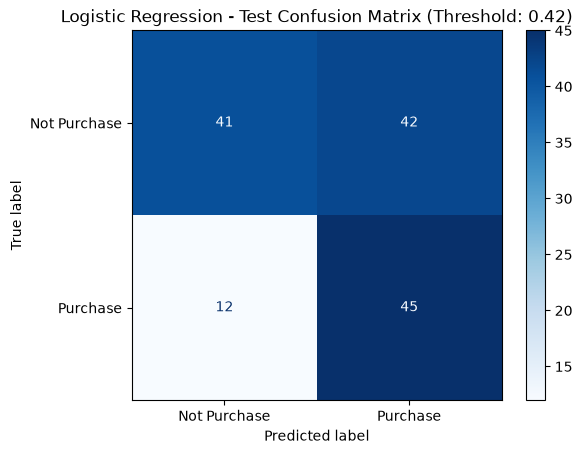

In [8]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred_default = best_model.predict(X_test)
test_pred_tuned = (test_prob >= best_threshold).astype(int)

print(f"Final Model Evaluated: {selected_model_name}")
print(f"Test ROC-AUC Score   : {roc_auc_score(y_test, test_prob):.4f}\n")

print(f"=== Test Report: Default Threshold (0.50) ===")
print(classification_report(y_test, test_pred_default, target_names=['Not Purchase', 'Purchase']))

print(f"=== Test Report: CV-Tuned Threshold ({best_threshold:.4f}) ===")
print(classification_report(y_test, test_pred_tuned, target_names=['Not Purchase', 'Purchase']))

cm = confusion_matrix(y_test, test_pred_tuned)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Purchase', 'Purchase'])
disp.plot(cmap=plt.cm.Blues)
plt.title(f"{selected_model_name} - Test Confusion Matrix (Threshold: {best_threshold:.2f})")
plt.show()

# 9. Model Serialization & Production Inference

In [9]:
model_path = 'models/purchase_bundle.joblib'
joblib.dump({
    "model": best_model,
    "threshold": best_threshold,
    "features": all_features
}, model_path)

print(f"Model bundle saved successfully to {model_path}")

loaded_bundle = joblib.load(model_path)
loaded_pipeline = loaded_bundle["model"]
loaded_threshold = loaded_bundle["threshold"]
loaded_features = loaded_bundle["features"]

real_raw_df = pd.read_csv('data/new_customers.csv')
real_df = add_features(real_raw_df)

real_prob = loaded_pipeline.predict_proba(real_df[loaded_features])[:, 1]
real_pred = (real_prob >= loaded_threshold).astype(int)

df_result = pd.DataFrame({
    'customer_id': real_df['customer_id'],
    'purchase_probability': np.round(real_prob, 4),
    'predicted_purchase': real_pred
})

output_path = 'output/predictions.csv'
df_result.to_csv(output_path, index=False)
print(f"Prediction saved to {output_path}")
df_result.head(10)

Model bundle saved successfully to models/purchase_bundle.joblib
Prediction saved to output/predictions.csv


,customer_id,purchase_probability,predicted_purchase
0,CUST-0701,0.4966,1
1,CUST-0702,0.1461,0
2,CUST-0703,0.3340,0
3,CUST-0704,0.2333,0
4,CUST-0705,0.4943,1
5,CUST-0706,0.4123,0
6,CUST-0707,0.3174,0
7,CUST-0708,0.9346,1
8,CUST-0709,0.6375,1
9,CUST-0710,0.4076,0
